## Análisis de Raster de pendiente.


In [1]:
import pandas as pd 
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent
from rasterio.windows import from_bounds
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer
import shapely
from rasterio.mask import mask
from shapely.geometry import mapping
from shapely.geometry import box
from rasterio.transform import xy
from collections import Counter
from pathlib import Path

In [2]:
parcelas_gdf = gpd.read_file('../../DataSet/DATASET_RETO_AGRO_2026/Parcelas_Reto_AGC_CONJUNTO_70_30/Parcelas_Reto_AGC_CONJUNTO.shp')

parcelas_gdf.head()

,Cultivo,ID_POLIGON,área_ha,Municipio,Estado,CONJUNTO,geometry
0,Cebada,AGC_196,8.57,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.57739 19.65802 0, -98.57751 19..."
1,Cebada,AGC_044,0.68,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58655 19.62943 0, -98.5862 19...."
2,Cebada,AGC_020,8.34,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58494 19.6278 0, -98.58656 19...."
3,CEBADA,AGC_174,6.89,Cuautepec de Hinojosa,Hidalgo,PREDICCION,"POLYGON Z ((-98.30604 19.9 0, -98.30486 19.899..."
4,CEBADA,AGC_083,2.87,Cuautepec de Hinojosa,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.29383 19.8882 0, -98.29378 19...."


In [3]:
print(f'Shape: {parcelas_gdf.shape}')
print(f'CRS: {parcelas_gdf.crs}')
print(f'Columns: {parcelas_gdf.columns}')

Shape: (197, 7)
CRS: EPSG:4326
Columns: Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')


In [5]:
parcela = parcelas_gdf[parcelas_gdf['ID_POLIGON'] == 'AGC_001'].copy()

print(parcela[["ID_POLIGON", "área_ha", "CONJUNTO"]])
print(f'CRS: {parcela.crs}')
print(f'Geometría: {parcela.geometry.iloc[0].geom_type}')

    ID_POLIGON  área_ha       CONJUNTO
196    AGC_001     7.61  ENTRENAMIENTO
CRS: EPSG:4326
Geometría: Polygon


Los datos de topografía vienen diferentes a los de precipitación y temperatura, para que se puedan utilizar juntos realizamos una reproyección, para que estén del mismo formato.


In [6]:
parcela_repro = parcela.to_crs("EPSG:6372")

print(f'Parcel original: {parcela.crs}')
print(f'Parcel reproyectada: {parcela_repro.crs}')

Parcel original: EPSG:4326
Parcel reproyectada: EPSG:6372


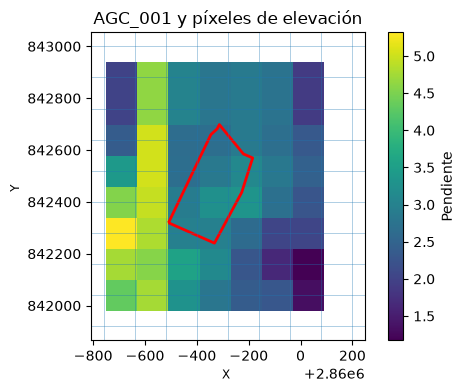

In [7]:
pend_path = '../../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Pendiente_INEGI_CEM4_120m_grados.tif'

with rasterio.open(pend_path) as src:

    # Límites de AGC_001
    xmin, ymin, xmax, ymax = parcela_repro.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    pendiente = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    pendiente = pendiente.astype(float)
    pendiente[pendiente == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        pendiente,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    pendiente,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_repro.boundary.plot(
    ax=ax,
    linewidth=2,
    color='red'
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_001 y píxeles de elevación")
ax.set_xlabel("X ")
ax.set_ylabel("Y ")

plt.colorbar(
    im,
    ax=ax,
    label="Pendiente"
)

plt.show()

In [8]:
#Considereamos solo ls pixeles que tocan la parcela (all_touched=True)
with rasterio.open(pend_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    pend_parcela, transform_pend_parcela = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=True)
    
print(pend_parcela.shape)

(1, 5, 3)


In [9]:

pend_vals = pend_parcela[0]

print("Número total de celdas:", pend_vals.size)
print("Número de celdas válidas:", pend_vals.count())
print("Valores de elevación:")
print(pend_vals.compressed())

Número total de celdas: 15
Número de celdas válidas: 13
Valores de elevación:
[2.6671813 2.8821812 2.6671813 2.8537097 3.1004913 2.9079316 3.2534685
 3.3182275 2.9814613 2.9802706 2.6201558 3.5574577 3.1380274]


In [11]:
pixeles_pend = []

parcela_geom = parcela_repro.geometry.iloc[0]

for i in range(pend_vals.shape[0]):
    for j in range(pend_vals.shape[1]):
        
        #Si el pixel esta enmascarado lo ignoramos
        if pend_vals.mask[i, j]:
            continue
        
        #Esquina izquierda superior
        x_iz, y_up = xy(transform_pend_parcela, i, j, offset='ul')
        
        #Esquina inferior derecha
        x_der, y_down = xy(transform_pend_parcela, i, j, offset='lr')
        
        #Bounding box del pixle
        pixel = box(x_iz, y_down, x_der, y_up)        
        
        intersection = pixel.intersection(parcela_geom)
        
        area_intersection = intersection.area
        area_pixel = pixel.area
        proporcion = area_intersection / area_pixel
        
        pixeles_pend.append({
            "fila": i,
            "columna": j,
            "pendiente": pend_vals[i, j],
            "area_pixel_m2": area_pixel,
            "area_interseccion_m2": area_intersection,
            "proporcion": proporcion
        })

In [12]:
pixeles_pend_df = pd.DataFrame(pixeles_pend)

pixeles_pend_df.head()

,fila,columna,pendiente,area_pixel_m2,area_interseccion_m2,proporcion
0,0,1,2.667181,14400.0,2511.258297,0.174393
1,0,2,2.882181,14400.0,128.715312,0.008939
2,1,0,2.667181,14400.0,172.400625,0.011972
3,1,1,2.853710,14400.0,12309.640839,0.854836
4,1,2,3.100491,14400.0,7565.188185,0.525360


In [13]:
pendiente_ponderada = ((pixeles_pend_df['pendiente'] * pixeles_pend_df['area_interseccion_m2']).sum() / pixeles_pend_df['area_interseccion_m2'].sum())
print("Media all_touched=True:", pend_vals.mean())
print("Media ponderada:", pendiente_ponderada)

Media all_touched=True: 2.9944416926457333
Media ponderada: 3.039547531881103


In [14]:
print("Área parcela:", parcela_geom.area)
print("Área suma intersecciones:", pixeles_pend_df["area_interseccion_m2"].sum())

Área parcela: 75685.78283383907
Área suma intersecciones: 75685.78283386417


In [15]:
area_total =parcela_geom.area

area_valida = pixeles_pend_df["area_interseccion_m2"].sum()

cobertura_valida = area_valida / area_total

print("Área total de la parcela:", area_total)
print("Área válida:", area_valida)
print("Cobertura válida:", cobertura_valida)
print("Cobertura válida (%):", cobertura_valida * 100)

Área total de la parcela: 75685.78283383907
Área válida: 75685.78283386417
Cobertura válida: 1.0000000000003317
Cobertura válida (%): 100.00000000003317


In [16]:
def get_slope(parcela, raster_path):
    
    with rasterio.open(raster_path) as src:
        
        # Reproyectar parcela al CRS del raster
        parcela_raster = parcela.to_crs(src.crs)
        
        # Geometría de la parcela
        geom_parcela = parcela_raster.geometry.iloc[0]
        geom = [mapping(geom_parcela)]
        
        # Recortar raster alrededor de la parcela
        valores, transform = mask(
            src,
            geom,
            crop=True,
            filled=False,
            all_touched=True
        )
        
        # Área total
        area_total = geom_parcela.area
        
        area_valida = 0
        suma_ponderada = 0
        
        # Recorrer píxeles
        for fila in range(valores.shape[1]):
            for columna in range(valores.shape[2]):
                
                # Ignorar NoData
                if valores.mask[0, fila, columna]:
                    continue
                
                # Valor de pendiente
                pendiente = valores[0, fila, columna]
                
                # Coordenadas del píxel
                x_izq, y_sup = rasterio.transform.xy(
                    transform,
                    fila,
                    columna,
                    offset="ul"
                )
                
                x_der, y_inf = rasterio.transform.xy(
                    transform,
                    fila,
                    columna,
                    offset="lr"
                )
                
                # Geometría del píxel
                pixel = box(
                    x_izq,
                    y_inf,
                    x_der,
                    y_sup
                )
                
                # Intersección con la parcela
                interseccion = pixel.intersection(geom_parcela)
                
                area_interseccion = interseccion.area
                
                # Área válida
                area_valida += area_interseccion
                
                # Pendiente × área
                suma_ponderada += (
                    float(pendiente) *
                    area_interseccion
                )
        
        # Media ponderada
        if area_valida > 0:
            pendiente_media = suma_ponderada / area_valida
        else:
            pendiente_media = np.nan
        
        # Cobertura
        cobertura = area_valida / area_total
        
        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_pendiente": cobertura,
            "cobertura_pendiente_pct": cobertura * 100,
            "pendiente_media": pendiente_media
        }

In [17]:
parcela_001 = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_001"
].copy()

resultado_001_pendiente = get_slope(
    parcela_001,
    pend_path
)

print(resultado_001_pendiente)

{'area_total_m2': 75685.78283383907, 'area_valida_m2': 75685.78283386417, 'cobertura_pendiente': 1.0000000000003317, 'cobertura_pendiente_pct': 100.00000000003317, 'pendiente_media': 3.039547531881103}
